In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [13]:
df = pd.read_csv(
    r"C:\Users\user\Downloads\social_media_engagement_5000 (1).csv"
)

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [14]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Rows and Columns: (5000, 19)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']

Data Types:
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


In [15]:
likes_array = np.array(df["likes"])

print("First 10 likes:")
print(likes_array[:10])

print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))

First 10 likes:
[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611.    nan 14106.]
Average likes: nan
Maximum likes: nan
Minimum likes: nan


In [16]:
print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5000, 19)


In [19]:
df["posted_at"] = pd.to_datetime(
    df["posted_at"],
    dayfirst=True,
    errors="coerce"
)

print(df["posted_at"].dtype)

datetime64[us]


In [21]:
numeric_columns = [
    "age",
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "impression_count"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

In [22]:
for col in numeric_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

In [23]:
categorical_columns = [
    "gender",
    "country",
    "post_type",
    "post_category",
    "sentiment",
    "device"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

In [25]:
# Check missing values
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [26]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [27]:
# Check data types
print(df.dtypes)

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object


In [28]:
categorical_columns = [
    "gender",
    "country",
    "post_type",
    "post_category",
    "sentiment",
    "device"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

In [30]:
for col in ["likes", "comments", "shares", "watch_time_sec", "impression_count"]:
    if col in df.columns:
        print(col, "negative values:", (df[col] < 0).sum())

likes negative values: 0
comments negative values: 0
shares negative values: 0
watch_time_sec negative values: 0
impression_count negative values: 0


In [31]:
for col in ["likes", "comments", "shares", "watch_time_sec", "impression_count"]:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan
        df[col] = df[col].fillna(df[col].median())

In [32]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726.0,44650.0,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947.0,80216.0,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946.0,44858.0,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229.0,70455.0,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798.0,6019.0,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [33]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190.0,42977.0,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764.0,34196.0,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466.0,23680.0,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991.0,89013.0,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743.0,14234.0,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [34]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (5000, 19)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   float64       
 11  impression_count  5000 non-null   float64       
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [36]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [37]:
print("Post types:")
print(df["post_type"].unique())

print("\nNumber of post types:")
print(df["post_type"].nunique())

print("\nPost type distribution:")
print(df["post_type"].value_counts())

Post types:
<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

Number of post types:
4

Post type distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64


In [38]:
print(df["gender"].value_counts())

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64


In [39]:
print(df["sentiment"].value_counts())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [40]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000


In [41]:
df["engagement_score"] = (
    df["likes"] +
    df["comments"] +
    df["shares"]
)

df[["likes", "comments", "shares", "engagement_score"]].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [42]:
df["engagement_rate"] = (
    df["engagement_score"] / df["impression_count"]
) * 100

df["engagement_rate"] = df["engagement_rate"].replace(
    [np.inf, -np.inf], np.nan
)

df["engagement_rate"] = df["engagement_rate"].fillna(0)

df[["engagement_score", "engagement_rate"]].head()

,engagement_score,engagement_rate
0,8522.0,19.086226
1,16163.0,20.149347
2,6161.0,13.734451
3,7482.0,10.619544
4,16717.0,277.737166


In [43]:
df["hashtag_count"] = (
    df["hashtags"]
    .fillna("")
    .astype(str)
    .str.count("#")
)

df[["hashtags", "hashtag_count"]].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [44]:
avg_likes_post_type = df.groupby("post_type")["likes"].mean().sort_values(
    ascending=False
)

print(avg_likes_post_type)

post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64


In [45]:
country_analysis = df.groupby("country").agg(
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement=("engagement_rate", "mean")
).sort_values("average_engagement", ascending=False)

country_analysis

,average_likes,average_comments,average_shares,average_engagement
country,,,,
brazil,9886.689484,1490.434524,1008.859127,153.691359
australia,10294.124746,1485.803245,1029.693712,132.523254
france,10372.876008,1478.695565,1051.812500,114.631358
uae,10227.487078,1541.214712,989.075547,110.797674
canada,10063.066277,1546.582846,996.245614,91.444308
uk,9935.650101,1463.042596,985.681542,85.199623
japan,10088.862288,1530.434322,959.351695,77.006522
germany,10130.458163,1531.826531,973.379592,75.603908
india,9962.468224,1494.917757,1035.315888,66.510921


In [46]:
sentiment_analysis = df.groupby("sentiment").agg(
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement=("engagement_rate", "mean")
).sort_values("average_engagement", ascending=False)

sentiment_analysis

,average_likes,average_comments,average_shares,average_engagement
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,103.829865
neutral,9923.194499,1528.404060,996.565160,99.072780
positive,10180.062077,1480.650617,1005.086749,91.913761


In [47]:
stats_columns = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate"
]

if "followers" in df.columns:
    stats_columns.append("followers")
elif "followers_count" in df.columns:
    stats_columns.append("followers_count")

for col in stats_columns:
    print("\n==============================")
    print("Column:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))


Column: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183877
Variance: 32516145.65382401
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0

Column: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458984
Variance: 733409.5049169434
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25

Column: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758852
Variance: 325875.65933950787
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0

Column: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916.0
Standard Deviation: 2308.0964590420845
Variance: 5327309.264242608
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

Column: engagement_rate
Mean: 96.38801761445886
Median: 25.473799907055337
Mode: 0.6362908833291788
Standard Deviation: 531.6985069009031
Variance: 282703.30224064976
25th Percentile: 14.6901

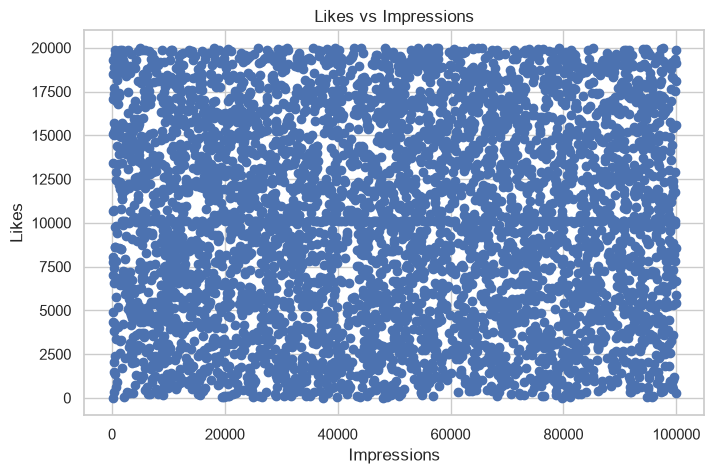

In [48]:
plt.figure(figsize=(8,5))

plt.scatter(df["impression_count"], df["likes"])

plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")

plt.show()

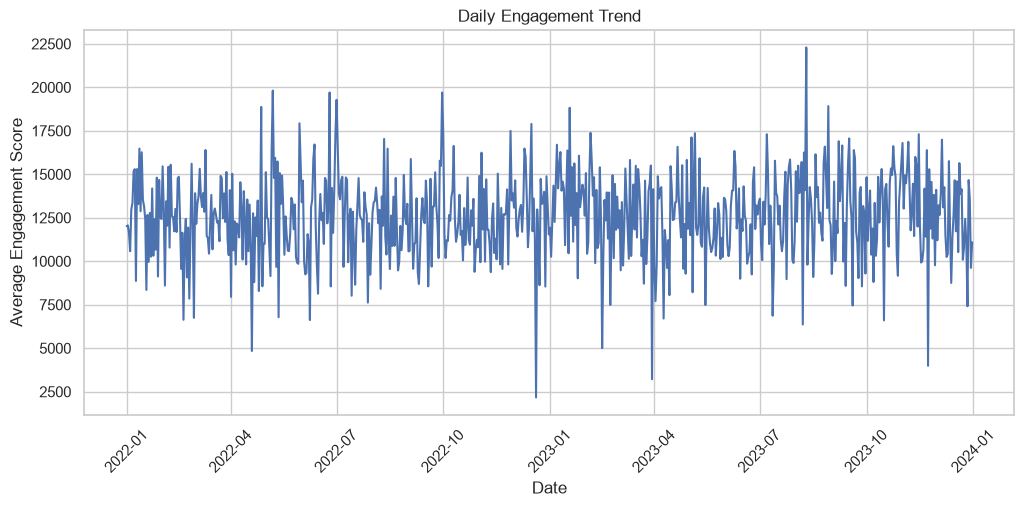

In [49]:
daily_engagement = df.groupby(
    df["posted_at"].dt.date
)["engagement_score"].mean()

plt.figure(figsize=(12,5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.title("Daily Engagement Trend")

plt.xticks(rotation=45)
plt.show()

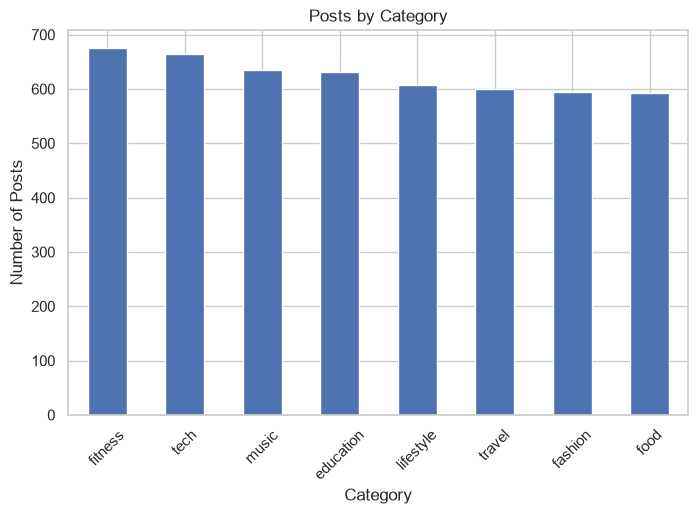

In [50]:
category_counts = df["post_category"].value_counts()

plt.figure(figsize=(8,5))

category_counts.plot(kind="bar")

plt.xlabel("Category")
plt.ylabel("Number of Posts")
plt.title("Posts by Category")

plt.xticks(rotation=45)
plt.show()

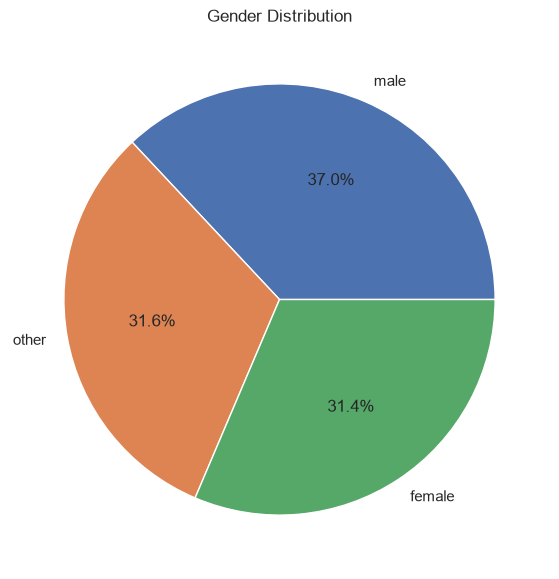

In [51]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%"
)

plt.title("Gender Distribution")

plt.show()

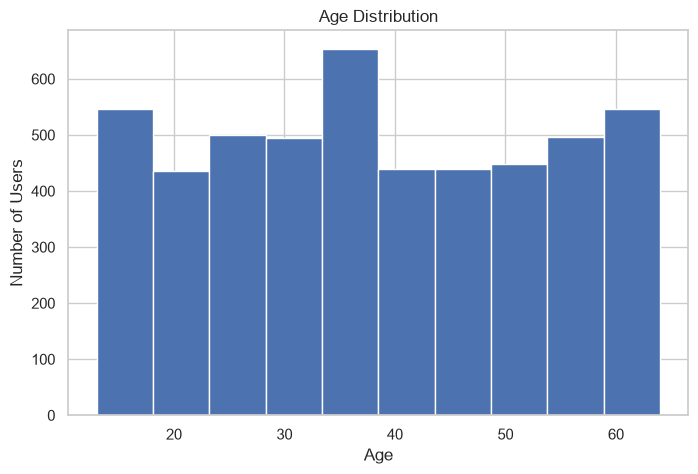

In [52]:
plt.figure(figsize=(8,5))

plt.hist(df["age"], bins=10)

plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.title("Age Distribution")

plt.show()

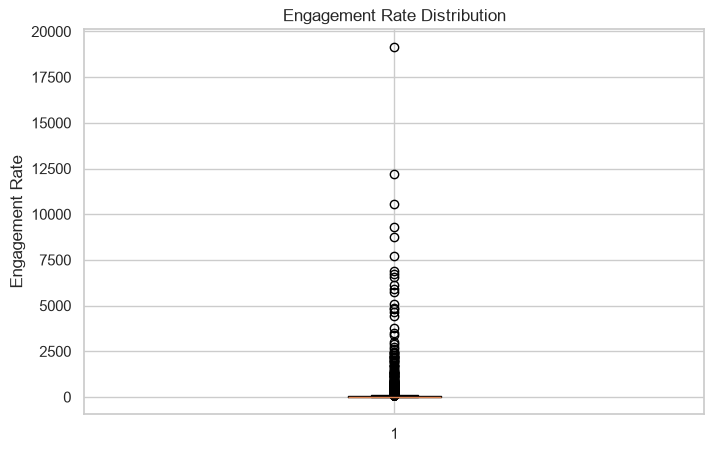

In [53]:
plt.figure(figsize=(8,5))

plt.boxplot(df["engagement_rate"].dropna())

plt.ylabel("Engagement Rate")
plt.title("Engagement Rate Distribution")

plt.show()

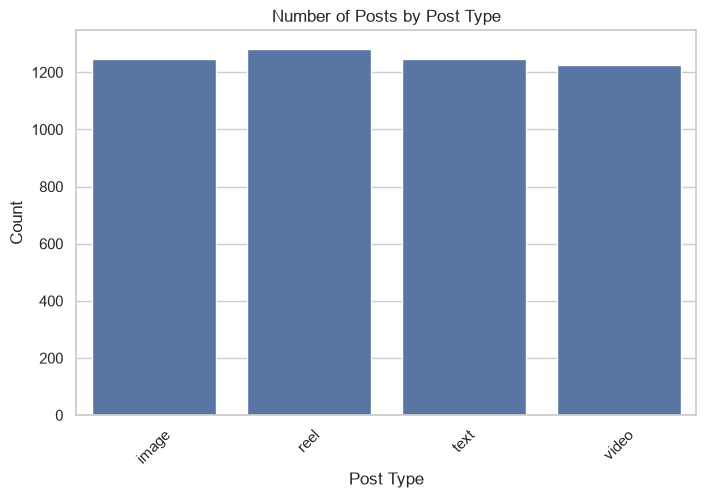

In [54]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="post_type")

plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")

plt.xticks(rotation=45)
plt.show()

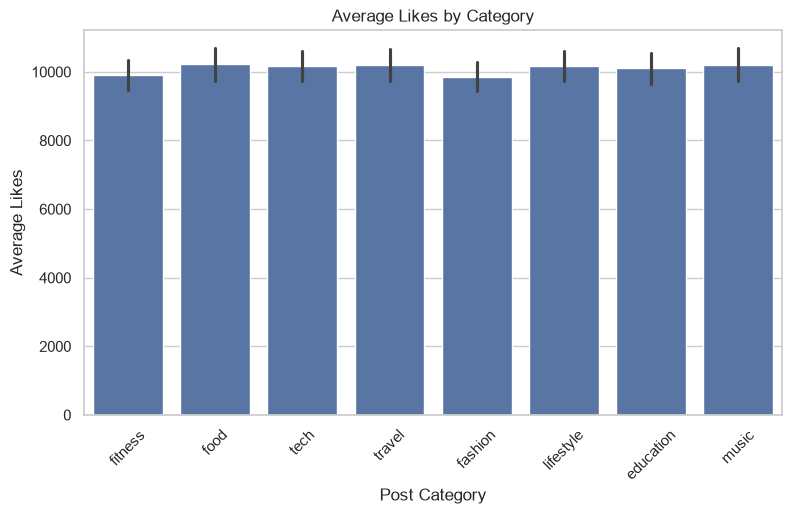

In [55]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x="post_category",
    y="likes",
    estimator="mean"
)

plt.title("Average Likes by Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")

plt.xticks(rotation=45)
plt.show()

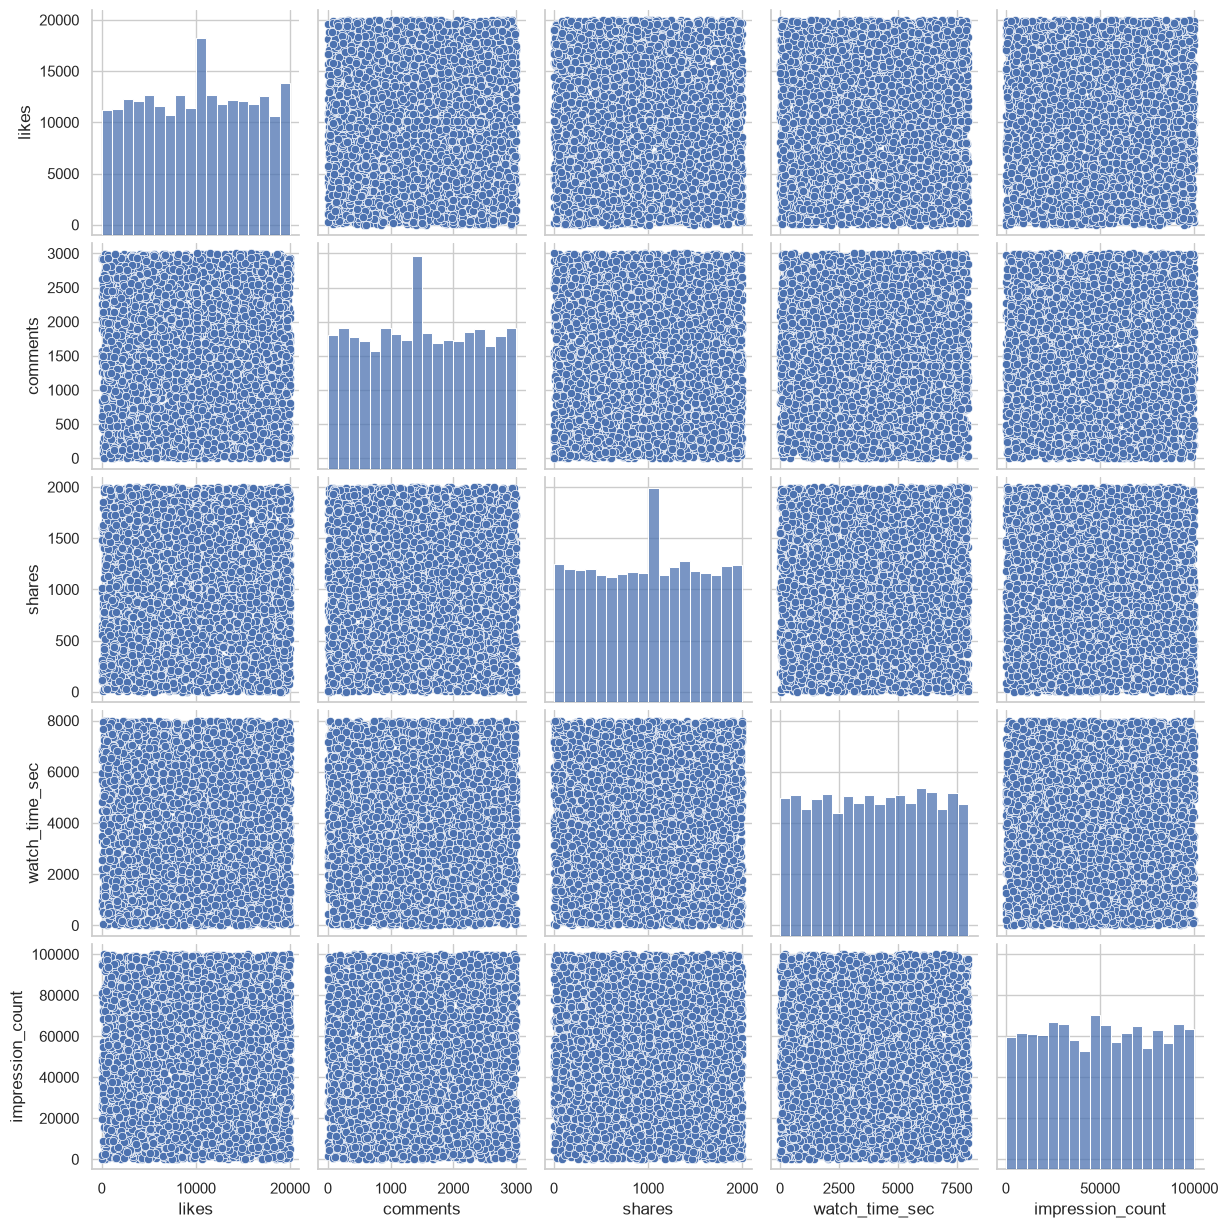

In [58]:
sns.pairplot(
    df[[
        "likes",
        "comments",
        "shares",
        "watch_time_sec",
        "impression_count"
    ]].dropna()
)

plt.show()

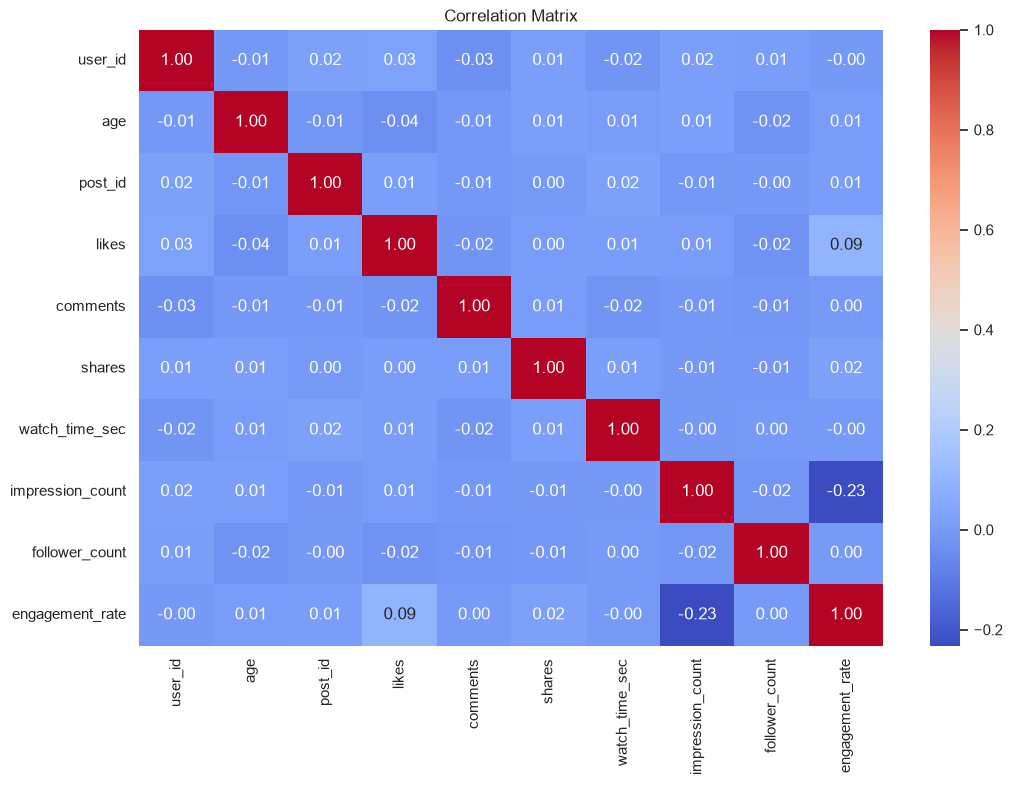

In [59]:
plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [61]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'engagement_score', 'hashtag_count']


In [62]:
df["engagement_score"] = (
    df["likes"] +
    df["comments"] +
    df["shares"]
)

df[["likes", "comments", "shares", "engagement_score"]].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [63]:
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=df,
    x="device",
    y="engagement_score"
)

plt.title("Engagement vs Device")
plt.xlabel("Device")
plt.ylabel("Engagement Score")

plt.show()

ValueError: Could not interpret value `device` for `x`. An entry with this name does not appear in `data`.

<Figure size 800x500 with 0 Axes>

In [64]:
df["likes"] = pd.to_numeric(df["likes"], errors="coerce")
df["comments"] = pd.to_numeric(df["comments"], errors="coerce")
df["shares"] = pd.to_numeric(df["shares"], errors="coerce")

df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

df["device"] = df["device"].astype(str).str.strip().str.lower()

KeyError: 'device'

In [65]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'engagement_score', 'hashtag_count']


In [66]:
print([col for col in df.columns if "device" in col.lower()])

['device_type']


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 20.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 20.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 39.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, U

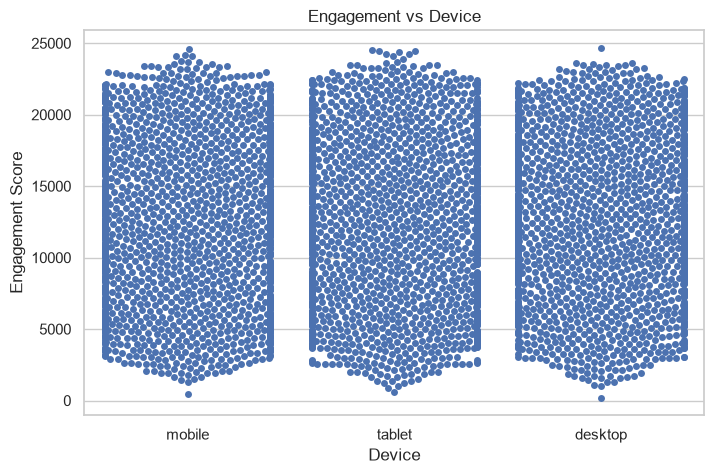

In [67]:
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=df,
    x="device_type",
    y="engagement_score"
)

plt.title("Engagement vs Device")
plt.xlabel("Device")
plt.ylabel("Engagement Score")
plt.show()

In [24]:
print("Column: follower_count")
print("Mean:", df["follower_count"].mean())
print("Median:", df["follower_count"].median())
print("Mode:", df["follower_count"].mode()[0])
print("Standard Deviation:", df["follower_count"].std())
print("Variance:", df["follower_count"].var())
print("25th Percentile:", df["follower_count"].quantile(0.25))
print("50th Percentile:", df["follower_count"].quantile(0.50))
print("75th Percentile:", df["follower_count"].quantile(0.75))

Column: follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502
Standard Deviation: 230927.88453461003
Variance: 53327687855.63019
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\user\Downloads\social_media_engagement_5000 (1).csv")

In [5]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [6]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [8]:
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]

In [9]:
df.groupby("post_type")["engagement_score"].mean().sort_values(ascending=False)

post_type
video    12658.675844
image    12627.062882
reel     12560.733850
text     12529.878199
Name: engagement_score, dtype: float64

In [11]:
df.groupby("post_category")["engagement_score"].mean().sort_values(ascending=False)

post_category
music        12896.741710
food         12656.661710
tech         12649.633117
lifestyle    12616.940109
travel       12595.420857
education    12594.467826
fitness      12483.886614
fashion      12249.938889
Name: engagement_score, dtype: float64

In [12]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [13]:
df.groupby("age")["engagement_score"].mean().sort_values(ascending=False)

age
49.0    14486.547619
17.0    14053.046512
33.0    13874.568182
39.0    13487.900000
36.0    13458.829787
38.0    13334.314815
20.0    13233.418919
14.0    13228.698925
24.0    13220.806122
50.0    13196.387500
25.0    13144.270000
32.0    13090.390805
29.0    13087.306122
15.0    12900.486486
30.0    12892.000000
34.0    12805.974359
56.0    12779.714286
45.0    12719.130952
62.0    12710.000000
13.0    12680.452055
31.0    12664.168831
48.0    12653.333333
43.0    12566.987500
21.0    12564.265823
44.0    12515.756410
23.0    12480.202703
18.0    12477.159091
27.0    12453.470588
52.0    12433.551282
61.0    12378.804598
35.0    12369.901961
42.0    12358.383562
16.0    12330.134146
57.0    12283.626374
46.0    12264.898734
51.0    12208.828283
22.0    12207.925000
54.0    12110.096154
60.0    12089.641975
64.0    12053.233333
41.0    12039.780220
59.0    11972.592105
28.0    11960.357143
37.0    11932.045455
26.0    11914.012500
63.0    11907.000000
19.0    11839.535714
47.0    1

In [14]:
df.groupby("is_verified")["engagement_score"].mean()

is_verified
False    12617.413223
True     12379.117517
Name: engagement_score, dtype: float64

In [16]:
df["posted_at"] = pd.to_datetime(df["posted_at"], dayfirst=True)

In [17]:
df["hour"] = df["posted_at"].dt.hour

In [18]:
df.groupby("hour")["impression_count"].mean().sort_values(ascending=False)

hour
0    50013.7328
Name: impression_count, dtype: float64

In [19]:
df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

In [20]:
df.groupby("sentiment")["engagement_score"].mean().sort_values(ascending=False)

sentiment
negative    12745.962670
positive    12593.029963
neutral     12459.355160
Name: engagement_score, dtype: float64

In [21]:
df[df["sentiment"].isin(["negative", "neutral"])] \
.groupby("sentiment")["engagement_score"].mean() \
.sort_values(ascending=False)

sentiment
negative    12745.96267
neutral     12459.35516
Name: engagement_score, dtype: float64

In [22]:
df[df["sentiment"].isin(["negative", "neutral"])] \
.groupby("sentiment")["engagement_score"].mean()

sentiment
negative    12745.96267
neutral     12459.35516
Name: engagement_score, dtype: float64

# Final Insights

## Content Performance
- Video posts have the highest average engagement score among the post types.
- Image posts also show strong engagement, followed by reels and text posts.

## User Trends
- Engagement varies across age groups, showing differences in user interaction.
- Unverified accounts have a higher average engagement score than verified accounts in this dataset.

## Behavioral Insights
- The analysis was performed to identify the time of day associated with impressions.
- Device-wise analysis was used to examine differences in engagement across mobile, tablet, and desktop users.

## Sentiment Analysis
- Negative sentiment posts have the highest average engagement score.
- Neutral sentiment posts have the lowest average engagement score among the negative and neutral posts analyzed.
- This indicates that sentiment is associated with differences in engagement levels in this dataset.

# Conclusion

The Social Media Engagement Analytics project analyzed user engagement using likes, comments, shares, impressions, watch time, and other metrics.

The analysis showed differences in engagement across post types, categories, countries, devices, age groups, verification status, and sentiment. Video posts had the highest average engagement score among the analyzed post types.

Sentiment analysis showed that negative sentiment posts had the highest average engagement score, while neutral sentiment posts had lower engagement.

Overall, the analysis helped identify patterns in social media engagement and provided insights into content performance and user behavior.

# Summary

This project analyzed social media engagement data using Python, Pandas,
NumPy, Matplotlib, and Seaborn.

The analysis examined engagement across post types, content categories,
countries, age groups, verification status, devices, posting time, and
sentiment.

Video posts recorded the highest average engagement score among the
post types analyzed. The analysis also showed differences in engagement
across user and content characteristics.

Sentiment analysis showed that negative sentiment posts had the highest
average engagement score, while neutral posts had lower engagement.

Overall, the project demonstrates how data cleaning, exploratory analysis,
statistical analysis, visualization, and grouping can be used to identify
patterns in social media engagement and user behavior.